# Quality per Joule: Analysis of the Results

This notebook produces every number, table, and figure of the paper.

# 1. Setup and Utilities

Imports, the result groups, one table with a row per run, and three small helpers used by every later section.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import kendalltau, pearsonr

from evaluate import analysis as A

%matplotlib inline
A.save = lambda fig, path: fig.tight_layout()
pd.set_option("display.max_colwidth", None)

## 1.1 Loading All Runs into One Table

Four result groups: two stopping criteria (`fixed`, `target`) measured with two tools (`native`, `codegreen`).

In [4]:
GROUPS = {("fixed", "native"): "fixed_budget__native", ("fixed", "codegreen"): "fixed_budget_ddim100__codegreen",
          ("target", "native"): "target_quality_fid50_ddim100__native",
          ("target", "codegreen"): "target_quality_fid50_ddim100__codegreen"}
RAW = {key: A.load_runs(Path("results") / name) for key, name in GROUPS.items()}
SUMMARY = {key: A.summarize([A.run_row(r) for r in group]) for key, group in RAW.items()}  # input of the repository's plots


def flatten(run, criterion, tool):
    """One row per run: the repository's summary fields plus the extra values the paper reports."""
    energy, quality, inference = run["energy"], run["quality"], run["inference"]
    ddim, checks = inference.get("ddim_100", {}), run["dir"] / "fid_history.csv"
    return {
        "criterion": criterion, "tool": tool, **A.run_row(run),
        "train_s": energy["train"]["duration_s"], "sampling_j": energy["final_sampling"]["total_j"],
        "idle_w": run["idle_power_w"]["total"], "recon_mse": quality["recon_mse"],
        "inference_s_per_1k": inference[quality["final_sampler"]]["s_per_1k"],
        "ddim_j_per_1k": ddim.get("j_per_1k"), "ddim_s_per_1k": ddim.get("s_per_1k"),
        "ddim_flops_image": run["capacity"]["flops_per_image"].get("ddim_100"),
        "last_check_fid": pd.read_csv(checks).fid.iloc[-1] if checks.exists() else None,
    }


runs = pd.DataFrame([flatten(run, *key) for key, group in RAW.items() for run in group])
runs["energy_to_target_j"] = pd.to_numeric(runs.energy_to_target_j, errors="coerce")
runs[["qpj_train", "qpj_train_eval", "qpj_train_inference"]] *= 1e7  # QpJ in units of 1e-7, as in the paper
runs = runs.assign(
    power_w=runs.train_total_j / runs.train_s,                                    # average power while training
    inference_w=runs.inference_j_per_1k / runs.inference_s_per_1k,                # average power while sampling
    step_j=runs.train_total_j / runs.steps,                                       # energy per training step
    pj_per_flop=1e12 * runs.train_total_j / (runs.steps * runs.flops_train_step),
    net_cut=1 - runs.train_net_total_j / runs.train_total_j,                      # share removed by the idle baseline
    n_star=1000 * runs.train_total_j / runs.inference_j_per_1k,                   # break-even point (images)
    n_star_ddim=1000 * runs.train_total_j / runs.ddim_j_per_1k,
)
runs = runs.assign(t_star_min=runs.n_star * runs.inference_s_per_1k / 6e4,        # time to generate N* images
                   t_star_ddim_min=runs.n_star_ddim * runs.ddim_s_per_1k / 6e4)

native = runs[runs.tool == "native"]  # the paper reports Native measurements
fixed, target = (native[native.criterion == c] for c in ("fixed", "target"))

## 1.2 Helper Functions

In [5]:
def by_model(df):
    """Per-model means over seeds, in the paper's model order."""
    return df.groupby("model", sort=False).mean(numeric_only=True)


def table(df, columns):
    """Paper-style table: one row per model, one 'mean ± std' cell per column = (field, scale, digits)."""
    stats = df.groupby("model", sort=False)
    cells = {name: [f"{m * scale:,.{digits}f} ± {sd * scale:,.{digits}f}"
                    for m, sd in zip(stats[field].mean(), stats[field].std())]
             for name, (field, scale, digits) in columns.items()}
    return pd.DataFrame(cells, index=[A.NAMES[m] for m in df.model.unique()]).replace("nan ± nan", "–")


def show(numbers, digits=1):
    """Display labelled numbers as a small table."""
    values = [f"{v:,.{digits}f}" if isinstance(v, float) else f"{v:,}" if isinstance(v, int) else v for v in numbers.values()]
    return pd.DataFrame({"value": values}, index=list(numbers))


def ranking(df, field):
    """Models ordered from the highest to the lowest mean of a field."""
    return " > ".join(A.NAMES[m] for m in by_model(df)[field].sort_values(ascending=False).index)


span = lambda s, scale=1, unit="", digits=0: f"{s.min() * scale:,.{digits}f} to {s.max() * scale:,.{digits}f}{unit}"

## 1.3 Completeness Check

Every group must hold 5 models × 3 seeds, all finished.

In [6]:
status = runs.groupby(["criterion", "tool"]).agg(runs=("seed", "size"), models=("model", "nunique"),
                                                 statuses=("status", lambda s: ", ".join(sorted(set(s)))))
assert (status.runs == 15).all() and (status.models == 5).all(), "expected 5 models x 3 seeds in every group"
status

runs  models        statuses
criterion tool                                   
fixed     codegreen    15       5       completed
          native       15       5       completed
target    codegreen    15       5  target_reached
          native       15       5  target_reached

# 2. Measurement Consistency: Native versus CodeGreen

Checks whether the conclusions depend on the measurement tool (Section III-A of the paper).

## 2.1 Correlation between the Readings of the Two Tools

Each energy measurement of a Native run (training, periodic FID checks, final sampling, inference per 1,000 images)
is paired with the same measurement of the CodeGreen run with the same model, seed, and stopping criterion.

In [7]:
PHASES = ["train_total_j", "eval_total_j", "sampling_j", "inference_j_per_1k"]
pairs = (runs.melt(["criterion", "model", "seed", "tool"], PHASES, "phase", "joules")
             .pivot(index=["criterion", "model", "seed", "phase"], columns="tool", values="joules")
             .query("native > 0"))  # the fixed budget has no periodic checks
pearson, kendall = pearsonr(pairs.native, pairs.codegreen), kendalltau(pairs.native, pairs.codegreen)
show({"Paired measurements": len(pairs), "Pearson r": float(pearson.statistic),
      "Kendall tau": float(kendall.statistic), "Kendall p-value": f"{kendall.pvalue:.1e}"}, digits=4)

,value
Paired measurements,105
Pearson r,0.9999
Kendall tau,0.9099
Kendall p-value,4.7e-43


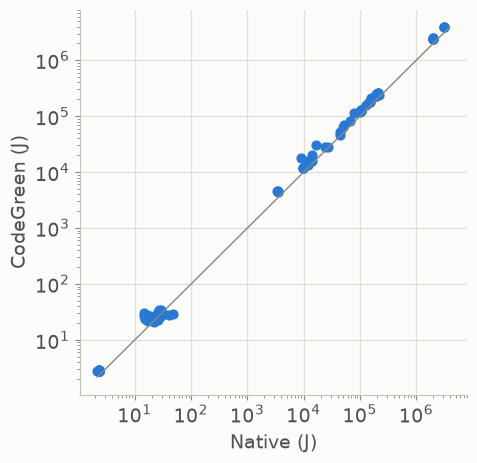

In [8]:
ax = pairs.plot.scatter("native", "codegreen", loglog=True, figsize=(5, 5), color=A.COLORS["ae"], s=40)
ax.plot(*[[pairs.min().min(), pairs.max().max()]] * 2, color=A.MUTED, linewidth=1)  # identity line
ax.set(xlabel="Native (J)", ylabel="CodeGreen (J)");

## 2.2 Absolute Difference: Energy per Step, Idle Baseline, and Net Energy

Energy is compared per training step, because under the target-quality criterion the two tools' runs stop at different epochs.

In [9]:
gap = runs.pivot_table(index=["criterion", "model"], columns="tool", values="step_j", sort=False)
gap["CodeGreen above Native (%)"] = 100 * (gap.codegreen / gap.native - 1)
gap.rename(index=A.NAMES).round(3)

tool               native  codegreen  CodeGreen above Native (%)
criterion model                                                 
fixed     AE        0.665      0.792                      19.155
          VAE       0.686      0.836                      21.795
          DCGAN     0.979      1.173                      19.784
          WGAN-GP   6.288      7.472                      18.830
          DDPM     20.578     25.475                      23.794
target    AE        0.666      0.787                      18.172
          VAE       0.687      0.832                      20.960
          DCGAN     0.958      1.151                      20.157
          WGAN-GP   6.304      7.454                      18.246
          DDPM     20.478     25.204                      23.080

In [10]:
tools = runs.groupby("tool")
show({"CodeGreen above Native, energy per training step": span(gap["CodeGreen above Native (%)"], unit=" %"),
      **{f"Idle baseline, {tool}": span(g.idle_w, unit=" W") for tool, g in tools},
      **{f"Training energy removed by the idle baseline, {tool}": span(g.net_cut, 100, " %") for tool, g in tools}})

,value
"CodeGreen above Native, energy per training step",18 to 24 %
"Idle baseline, codegreen",75 to 103 W
"Idle baseline, native",22 to 36 W
"Training energy removed by the idle baseline, codegreen",36 to 55 %
"Training energy removed by the idle baseline, native",13 to 22 %


## 2.3 Do Both Tools Rank the Models Identically?

Models ordered from highest to lowest, by training energy and by QpJ in every energy scope
(T = training, E = periodic checks, S = final sampling).

In [11]:
METRICS = {"train_total_j": "Training energy", "qpj_train": "QpJ (T)", "qpj_train_eval": "QpJ (T+E)",
           "qpj_train_inference": "QpJ (T+S)"}
agreement = pd.DataFrame([{"criterion": c, "metric": name, **{tool: ranking(g[g.tool == tool], field) for tool in ("native", "codegreen")}}
                          for c, g in runs.groupby("criterion") for field, name in METRICS.items()]).set_index(["criterion", "metric"])
agreement["identical"] = agreement.native == agreement.codegreen
agreement

native  \
criterion metric                                               
fixed     Training energy  DDPM > WGAN-GP > DCGAN > VAE > AE   
          QpJ (T)          DCGAN > WGAN-GP > AE > VAE > DDPM   
          QpJ (T+E)        DCGAN > WGAN-GP > AE > VAE > DDPM   
          QpJ (T+S)        DCGAN > WGAN-GP > AE > VAE > DDPM   
target    Training energy  DDPM > VAE > WGAN-GP > AE > DCGAN   
          QpJ (T)          DCGAN > AE > WGAN-GP > DDPM > VAE   
          QpJ (T+E)        DCGAN > AE > WGAN-GP > DDPM > VAE   
          QpJ (T+S)        DCGAN > AE > WGAN-GP > VAE > DDPM   

                                                   codegreen  identical  
criterion metric                                                         
fixed     Training energy  DDPM > WGAN-GP > DCGAN > VAE > AE       True  
          QpJ (T)          DCGAN > WGAN-GP > AE > VAE > DDPM       True  
          QpJ (T+E)        DCGAN > WGAN-GP > AE > VAE > DDPM       True  
          QpJ (T+S)        DCGAN > WGAN-GP > AE > VAE > DDPM       True  
target    Training energy  DDPM > VAE > WGAN-GP > AE > DCGAN       True  
          QpJ (T)          DCGAN > AE > WGAN-GP > DDPM > VAE       True  
          QpJ (T+E)        DCGAN > AE > WGAN-GP > DDPM > VAE       True  
          QpJ (T+S)        DCGAN > AE > WGAN-GP > VAE > DDPM       True

# 3. RQ1: How Much Energy Does Each Family Consume, and Do FLOPs Reflect It?

All values in this section are Native measurements under the fixed budget (30 epochs).

## 3.1 Table I: Model Size and Computational Cost

In [15]:
m = by_model(fixed)
cost = pd.DataFrame({"Params (M)": m.params / 1e6, "GFLOPs per training step": m.flops_train_step / 1e9,
                     "GFLOPs per image": m.flops_image / 1e9, "GFLOPs per image (DDIM-100)": m.ddim_flops_image / 1e9})
cost.rename(index=A.NAMES).round(3).fillna("–")

/var/folders/t9/bkw7qt1s29s2vn5rr1v886_m0000gn/T/ipykernel_21852/1335061025.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  cost.rename(index=A.NAMES).round(3).fillna("–")


,Params (M),GFLOPs per training step,GFLOPs per image,GFLOPs per image (DDIM-100)
model,,,,
AE,2.367,6.895,0.036,–
VAE,2.892,6.996,0.036,–
DCGAN,1.847,13.458,0.036,–
WGAN-GP,1.847,79.555,0.036,–
DDPM,35.746,1194.366,12443.714,1244.371


## 3.2 Table II: Cost and Quality under the Fixed Budget

Mean ± standard deviation over three seeds. Inference is per 1,000 images; DDPM uses 1,000-step ancestral sampling.

In [16]:
table(fixed, {"Energy (kJ)": ("train_total_j", 1e-3, 1), "Time (min)": ("train_s", 1 / 60, 1),
              "Inference (J)": ("inference_j_per_1k", 1, 2), "Inference, DDIM-100 (J)": ("ddim_j_per_1k", 1, 0),
              "FID": ("final_fid", 1, 2)})

,Energy (kJ),Time (min),Inference (J),"Inference, DDIM-100 (J)",FID
AE,101.5 ± 2.4,10.1 ± 0.3,2.30 ± 0.01,–,42.81 ± 0.54
VAE,104.7 ± 0.5,10.7 ± 0.1,2.29 ± 0.01,–,50.44 ± 0.16
DCGAN,149.4 ± 2.3,14.7 ± 0.3,2.27 ± 0.03,–,11.43 ± 0.31
WGAN-GP,191.9 ± 3.1,19.6 ± 0.3,2.25 ± 0.08,–,20.76 ± 0.34
DDPM,"3,140.2 ± 10.5",315.0 ± 0.1,"201,413.97 ± 12,759.44","19,454 ± 19",5.44 ± 0.17


## 3.3 Training Energy: Spread across Models and Split by Component

In [17]:
E = m.train_total_j
show({"Lowest training energy, AE (kJ)": E.ae / 1e3, "Highest training energy, DDPM (MJ)": E.ddpm / 1e6,
      "DDPM / AE": E.ddpm / E.ae, "DCGAN / AE": E.dcgan / E.ae, "WGAN-GP / DCGAN": E.wgan_gp / E.dcgan,
      "WGAN-GP / AE": E.wgan_gp / E.ae})

,value
"Lowest training energy, AE (kJ)",101.5
"Highest training energy, DDPM (MJ)",3.1
DDPM / AE,30.9
DCGAN / AE,1.5
WGAN-GP / DCGAN,1.3
WGAN-GP / AE,1.9


In [18]:
shares = 100 * m[["train_gpu_j", "train_cpu_j", "train_ram_j"]].div(E, axis=0)
shares.columns = ["GPU (%)", "CPU (%)", "RAM (%)"]
shares.rename(index=A.NAMES).round(2)

,GPU (%),CPU (%),RAM (%)
model,,,
AE,60.41,39.19,0.41
VAE,59.45,40.13,0.42
DCGAN,60.75,38.85,0.40
WGAN-GP,58.82,40.74,0.44
DDPM,81.17,18.44,0.39


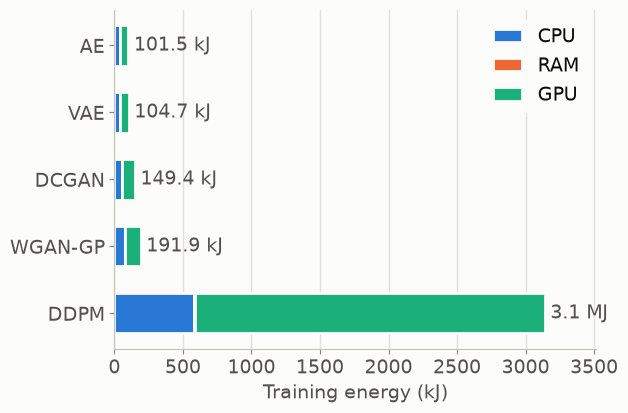

In [19]:
A.plot_energy_breakdown(SUMMARY["fixed", "native"], None)

## 3.4 FLOPs and Parameter Counts versus Measured Energy

The first three columns are relative to the AE. If FLOPs tracked energy, the first two would match.
Training FLOPs are FLOPs per step × steps, because a WGAN-GP step covers five batches.

In [20]:
relative = lambda s: s / s.ae
proxies = pd.DataFrame({"Energy (× AE)": relative(E), "Training FLOPs (× AE)": relative(m.steps * m.flops_train_step),
                        "Training time (× AE)": relative(m.train_s), "Params (M)": m.params / 1e6, "pJ per FLOP": m.pj_per_flop})
proxies.rename(index=A.NAMES).round(2)

,Energy (× AE),Training FLOPs (× AE),Training time (× AE),Params (M),pJ per FLOP
model,,,,,
AE,1.00,1.00,1.00,2.37,96.45
VAE,1.03,1.01,1.06,2.89,98.08
DCGAN,1.47,1.95,1.45,1.85,72.74
WGAN-GP,1.89,2.31,1.93,1.85,79.04
DDPM,30.94,173.21,31.10,35.75,17.23


In [21]:
show({"FLOPs overstate DDPM's training cost relative to the AE by (×)":
      proxies.loc["ddpm", "Training FLOPs (× AE)"] / proxies.loc["ddpm", "Energy (× AE)"]})

,value
FLOPs overstate DDPM's training cost relative to the AE by (×),5.6


## 3.5 Inference Energy: Single-Pass Models versus DDPM

In [22]:
single = m.drop("ddpm")
energy_ratio = m.inference_j_per_1k.ddpm / single.inference_j_per_1k.mean()
flops_ratio = m.flops_image.ddpm / single.flops_image.mean()
show({"Single-pass models (J per 1,000 images)": span(single.inference_j_per_1k, digits=2),
      "DDPM ancestral / single-pass, energy (×)": energy_ratio,
      "DDPM DDIM-100 / single-pass, energy (×)": m.ddim_j_per_1k.ddpm / single.inference_j_per_1k.mean(),
      "DDPM ancestral / DDIM-100, energy (×)": m.inference_j_per_1k.ddpm / m.ddim_j_per_1k.ddpm,
      "DDPM / single-pass, FLOPs per image (×)": flops_ratio,
      "FLOPs overstate the inference gap by (×)": flops_ratio / energy_ratio})

,value
"Single-pass models (J per 1,000 images)",2.25 to 2.30
"DDPM ancestral / single-pass, energy (×)","88,554.0"
"DDPM DDIM-100 / single-pass, energy (×)","8,553.4"
"DDPM ancestral / DDIM-100, energy (×)",10.4
"DDPM / single-pass, FLOPs per image (×)","343,900.4"
FLOPs overstate the inference gap by (×),3.9


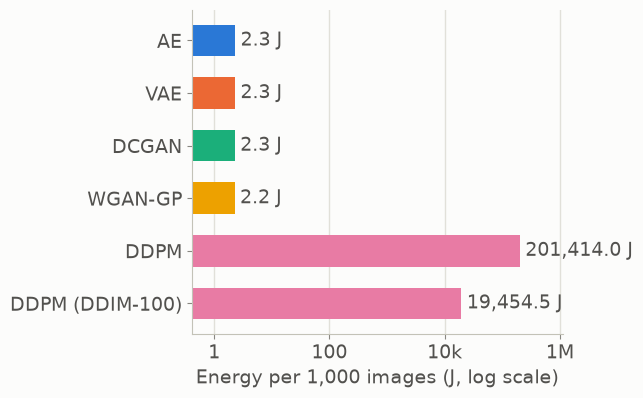

In [23]:
labels = [A.NAMES[k] for k in m.index] + ["DDPM (DDIM-100)"]
A.bar_chart(labels, [*m.inference_j_per_1k, m.ddim_j_per_1k.ddpm], [A.COLORS[k] for k in m.index] + [A.COLORS["ddpm"]],
            "Energy per 1,000 images (J, log scale)", None, lambda v: f"{v:,.1f} J")

## 3.6 Output Quality: FID and Reconstruction Error

Models ordered from best to worst FID. Reconstruction error (MSE on the test split) exists only for the AE and the VAE.

In [25]:
m[["final_fid", "recon_mse"]].sort_values("final_fid").rename(index=A.NAMES, columns={"final_fid": "FID", "recon_mse": "Reconstruction MSE"}).round(4).fillna("–")

/var/folders/t9/bkw7qt1s29s2vn5rr1v886_m0000gn/T/ipykernel_21852/3563367251.py:1: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  m[["final_fid", "recon_mse"]].sort_values("final_fid").rename(index=A.NAMES, columns={"final_fid": "FID", "recon_mse": "Reconstruction MSE"}).round(4).fillna("–")


,FID,Reconstruction MSE
model,,
DDPM,5.4369,–
DCGAN,11.4320,–
WGAN-GP,20.7551,–
AE,42.8115,0.0096
VAE,50.4394,0.0211


## 3.7 Figure 2: Training Energy and Final FID under the Fixed Budget

Each metric as a percentage of its highest value; labels give absolute values, and lower is better for both.

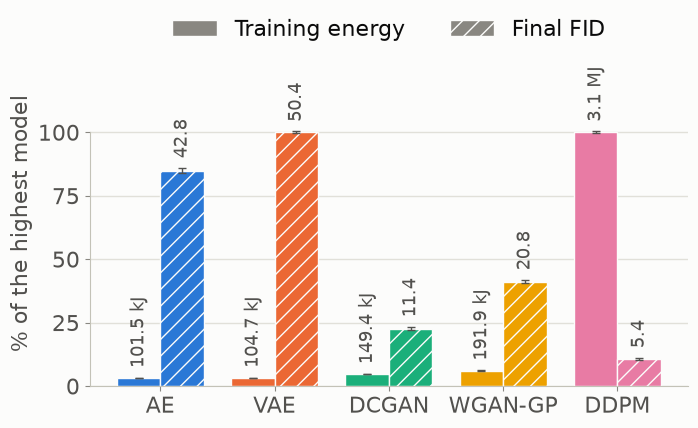

In [26]:
A.plot_energy_fid(SUMMARY["fixed", "native"], None)

# 4. RQ2: How Do the Families Compare in Quality per Joule, and How Robust Is the Ranking?

QpJ = 1 / (FID × energy), in units of 10⁻⁷ (higher is better), for three energy scopes:
T = training, T+E = training and periodic FID checks, T+S = training and final sampling of 10,000 images.

## 4.1 Table III: QpJ under Both Stopping Criteria

In [27]:
QPJ = {"QpJ T": ("qpj_train", 1, 2), "QpJ T+E": ("qpj_train_eval", 1, 2), "QpJ T+S": ("qpj_train_inference", 1, 2)}
pd.concat({"Fixed budget (30 epochs)": table(fixed, {k: QPJ[k] for k in ("QpJ T", "QpJ T+S")}),
           "Target quality (FID ≤ 50)": table(target, {"Epochs": ("epochs", 1, 1), "Energy-to-target (kJ)": ("energy_to_target_j", 1e-3, 1),
                                                       "FID": ("final_fid", 1, 2), **QPJ})}, axis=1)

Fixed budget (30 epochs)              Target quality (FID ≤ 50)  \
                           QpJ T      QpJ T+S                    Epochs   
AE                   2.30 ± 0.08  2.30 ± 0.08                 6.7 ± 1.5   
VAE                  1.89 ± 0.00  1.89 ± 0.00                37.0 ± 8.0   
DCGAN                5.86 ± 0.07  5.86 ± 0.07                 2.0 ± 0.0   
WGAN-GP              2.51 ± 0.03  2.51 ± 0.03                 7.3 ± 0.6   
DDPM                 0.59 ± 0.02  0.36 ± 0.01                 2.0 ± 0.0   

                                                                         \
        Energy-to-target (kJ)           FID         QpJ T       QpJ T+E   
AE                 22.6 ± 5.2  48.26 ± 1.09   9.53 ± 2.32   6.26 ± 1.50   
VAE              129.4 ± 28.0  48.89 ± 0.61   1.63 ± 0.37   1.09 ± 0.24   
DCGAN               9.7 ± 0.1  37.69 ± 2.09  27.28 ± 1.52  20.15 ± 1.16   
WGAN-GP            47.0 ± 3.9  45.32 ± 0.63   4.71 ± 0.43   3.71 ± 0.34   
DDPM              208.3 ± 2.6  12.15 ± 0.50   3.95 ± 0.13   2.02 ± 0.07   

                       
              QpJ T+S  
AE        9.52 ± 2.32  
VAE       1.63 ± 0.37  
DCGAN    27.21 ± 1.53  
WGAN-GP   4.71 ± 0.43  
DDPM      0.38 ± 0.01

## 4.2 Fixed Budget: QpJ Ratios and Dominated Models

A model is dominated when another model consumes less training energy and achieves a lower FID.

In [28]:
q = m.qpj_train
show({"DCGAN QpJ (× 1e-7)": q.dcgan, "DCGAN / WGAN-GP": q.dcgan / q.wgan_gp, "DCGAN / AE": q.dcgan / q.ae,
      "DCGAN / DDPM, training only": q.dcgan / q.ddpm,
      "DCGAN / DDPM, with final sampling": m.qpj_train_inference.dcgan / m.qpj_train_inference.ddpm,
      "DDPM / DCGAN, training energy": E.ddpm / E.dcgan, "DCGAN / DDPM, FID": m.final_fid.dcgan / m.final_fid.ddpm,
      "Final sampling of 10,000 images, single-pass models (J)": span(single.sampling_j)}, digits=2)

,value
DCGAN QpJ (× 1e-7),5.86
DCGAN / WGAN-GP,2.33
DCGAN / AE,2.54
"DCGAN / DDPM, training only",10.00
"DCGAN / DDPM, with final sampling",16.21
"DDPM / DCGAN, training energy",21.02
"DCGAN / DDPM, FID",2.10
"Final sampling of 10,000 images, single-pass models (J)",23 to 33


In [29]:
def dominated(df):
    """For each model, the models that are both cheaper to train and better in FID."""
    d = by_model(df)
    better = lambda a: [A.NAMES[b] for b in d.index if d.train_total_j[b] < d.train_total_j[a] and d.final_fid[b] < d.final_fid[a]]
    return pd.Series({A.NAMES[a]: ", ".join(better(a)) or "–" for a in d.index})


pd.DataFrame({"Dominated by (fixed budget)": dominated(fixed), "Dominated by (target quality)": dominated(target)})

,Dominated by (fixed budget),Dominated by (target quality)
AE,–,DCGAN
VAE,AE,"AE, DCGAN, WGAN-GP"
DCGAN,–,–
WGAN-GP,DCGAN,DCGAN
DDPM,–,–


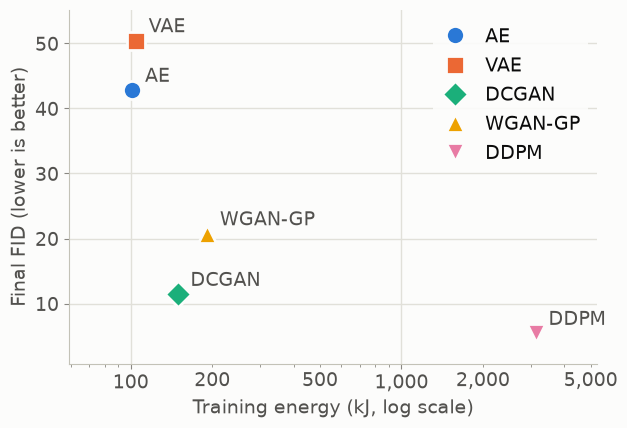

In [30]:
A.plot_fid_vs_energy(SUMMARY["fixed", "native"], None)

## 4.3 Target Quality: Energy Needed to Reach FID ≤ 50

Epochs to the target, energy relative to DCGAN, the overhead of the periodic FID checks, and the cost of the final sampling.

In [32]:
t = by_model(target)
pd.DataFrame({"Epochs (min to max)": target.groupby("model", sort=False).epochs.agg(lambda s: span(s)),
              "Energy-to-target (kJ)": t.energy_to_target_j / 1e3, "Energy-to-target (× DCGAN)": t.energy_to_target_j / t.energy_to_target_j.dcgan,
              "Periodic checks (kJ)": t.eval_total_j / 1e3, "Periodic checks (% of training)": 100 * t.eval_total_j / t.train_total_j,
              "Final sampling (kJ)": t.sampling_j / 1e3, "Final sampling (× training)": t.sampling_j / t.train_total_j}).rename(index=A.NAMES).round(2)

,Epochs (min to max),Energy-to-target (kJ),Energy-to-target (× DCGAN),Periodic checks (kJ),Periodic checks (% of training),Final sampling (kJ),Final sampling (× training)
model,,,,,,,
AE,5 to 8,22.59,2.32,11.76,52.06,0.02,0.00
VAE,29 to 45,129.39,13.27,64.51,49.86,0.02,0.00
DCGAN,2 to 2,9.75,1.00,3.45,35.37,0.02,0.00
WGAN-GP,7 to 8,47.05,4.83,12.73,27.05,0.02,0.00
DDPM,2 to 2,208.34,21.38,199.75,95.88,1957.02,9.39


In [33]:
show({"DCGAN / DDPM, QpJ with final sampling": t.qpj_train_inference.dcgan / t.qpj_train_inference.ddpm,
      "AE / DDPM, QpJ training only": t.qpj_train.ae / t.qpj_train.ddpm, "AE / DDPM, FID": t.final_fid.ae / t.final_fid.ddpm})

,value
"DCGAN / DDPM, QpJ with final sampling",71.5
"AE / DDPM, QpJ training only",2.4
"AE / DDPM, FID",4.0


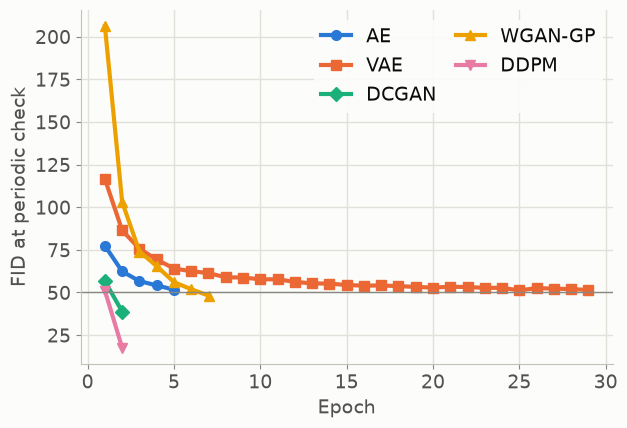

In [34]:
A.plot_lines(A.model_curves(RAW["target", "native"], A.fid_curve), "Epoch", "FID at periodic check", None, hline=50, log=False)

## 4.4 Robustness: Ranking by Stopping Criterion and Energy Scope

Models ordered from the highest to the lowest QpJ (and, in the last row, from the most to the least training energy).

In [35]:
pd.DataFrame({criterion: {name: ranking(df, field) for field, name in [*list(METRICS.items())[1:], list(METRICS.items())[0]]}
              for criterion, df in (("Fixed budget", fixed), ("Target quality", target))})

,Fixed budget,Target quality
QpJ (T),DCGAN > WGAN-GP > AE > VAE > DDPM,DCGAN > AE > WGAN-GP > DDPM > VAE
QpJ (T+E),DCGAN > WGAN-GP > AE > VAE > DDPM,DCGAN > AE > WGAN-GP > DDPM > VAE
QpJ (T+S),DCGAN > WGAN-GP > AE > VAE > DDPM,DCGAN > AE > WGAN-GP > VAE > DDPM
Training energy,DDPM > WGAN-GP > DCGAN > VAE > AE,DDPM > VAE > WGAN-GP > AE > DCGAN


## 4.5 Figure 3: Energy-to-Target and Final FID under the Target-Quality Criterion

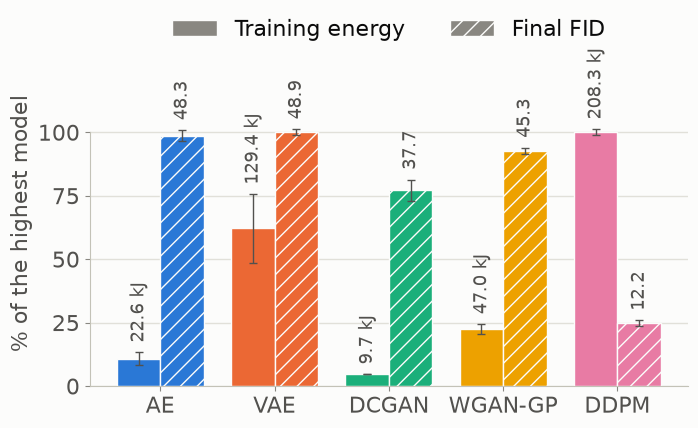

In [36]:
A.plot_energy_fid(SUMMARY["target", "native"], None)

# 5. RQ3: When Does Inference Energy Overtake Training Energy?

Break-even point N* = training energy / inference energy per image; t* is the time needed to generate N* images.

## 5.1 Table IV: Break-even Point and Generation Time

In [37]:
def breakeven(df):
    """N* and t* per model, with one row per DDPM sampler."""
    main = table(df, {"N* (images)": ("n_star", 1, 0), "t* (min)": ("t_star_min", 1, 1)}).rename(index={"DDPM": "DDPM (ancestral)"})
    ddim = table(df[df.model == "ddpm"], {"N* (images)": ("n_star_ddim", 1, 0), "t* (min)": ("t_star_ddim_min", 1, 1)})
    return pd.concat([main, ddim.rename(index={"DDPM": "DDPM (DDIM-100)"})])


pd.concat({"Fixed budget": breakeven(fixed), "Target quality": breakeven(target)}, axis=1)

Fixed budget                \
                             N* (images)      t* (min)   
AE                  44,207,550 ± 942,318    10.3 ± 0.2   
VAE                 45,780,096 ± 202,668    10.6 ± 0.1   
DCGAN                 65,944,983 ± 5,435    15.1 ± 0.3   
WGAN-GP           85,339,411 ± 2,262,604    19.4 ± 0.3   
DDPM (ancestral)          15,633 ± 1,002  288.8 ± 19.8   
DDPM (DDIM-100)            161,412 ± 695   299.0 ± 1.3   

                           Target quality              
                              N* (images)    t* (min)  
AE                  9,709,328 ± 2,198,077   2.3 ± 0.5  
VAE               56,001,355 ± 12,466,353  13.0 ± 2.9  
DCGAN                  4,261,502 ± 23,855   1.0 ± 0.0  
WGAN-GP            20,271,938 ± 1,428,976   4.7 ± 0.3  
DDPM (ancestral)                1,062 ± 2  19.7 ± 0.0  
DDPM (DDIM-100)               10,623 ± 37  19.7 ± 0.1

## 5.2 Break-even in Images, in Time, and at Deployment Scale

In [38]:
singles = native[native.model != "ddpm"].groupby(["criterion", "model"]).n_star.mean()
million_j = 1000 * m.inference_j_per_1k  # energy of one million images
show({"Single-pass N* (million images)": span(singles, 1e-6, digits=1),
      "DDPM N*, fixed budget (images)": round(m.n_star.ddpm), "DDPM N*, target quality (images)": round(t.n_star.ddpm),
      "DDIM-100 / ancestral N*, fixed budget": m.n_star_ddim.ddpm / m.n_star.ddpm,
      "One million DDPM images (MJ)": million_j.ddpm / 1e6, "One million DDPM images / training energy (×)": million_j.ddpm / E.ddpm,
      "One million single-pass images (kJ)": span(million_j.drop("ddpm"), 1e-3, digits=2),
      "One million single-pass images / training energy": span(million_j.drop("ddpm") / E.drop("ddpm"), 100, " %", 1)})

,value
Single-pass N* (million images),4.3 to 85.3
"DDPM N*, fixed budget (images)","15,633"
"DDPM N*, target quality (images)","1,062"
"DDIM-100 / ancestral N*, fixed budget",10.3
One million DDPM images (MJ),201.4
One million DDPM images / training energy (×),64.1
One million single-pass images (kJ),2.25 to 2.30
One million single-pass images / training energy,1.2 to 2.3 %


In [39]:
pd.DataFrame({"Training time (min)": m.train_s / 60, "Break-even time t* (min)": m.t_star_min,
              "Training power (W)": m.power_w, "Inference power (W)": m.inference_w}).rename(index=A.NAMES).round(1)

,Training time (min),Break-even time t* (min),Training power (W),Inference power (W)
model,,,,
AE,10.1,10.3,167.0,164.6
VAE,10.7,10.6,162.9,164.7
DCGAN,14.7,15.1,169.6,165.3
WGAN-GP,19.6,19.4,163.3,165.1
DDPM,315.0,288.8,166.1,181.8


## 5.3 Figure 4: Cumulative Inference Energy Relative to Training Energy

Target-quality criterion, mean over three seeds. Each line crosses the break-even line at its N*.

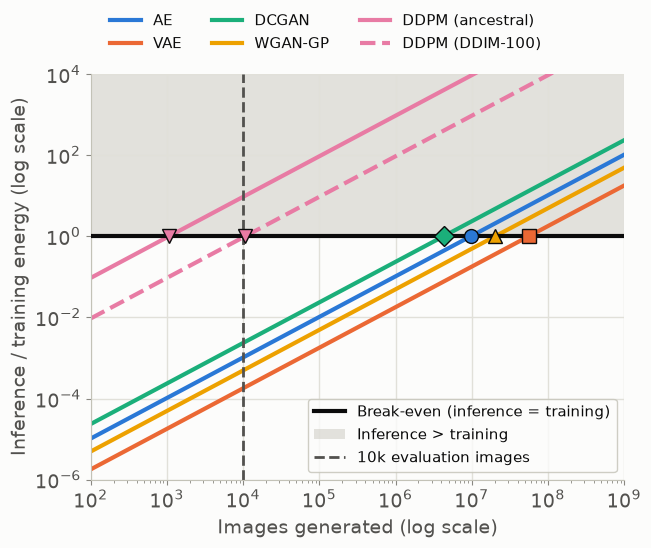

In [40]:
def plot_breakeven(df):
    """Inference energy of N images divided by training energy; solid = default sampler, dashed = DDIM-100."""
    n, means = np.logspace(2, 9, 200), by_model(df)
    fig, ax = plt.subplots(figsize=(6.4, 5.4), layout="constrained")
    for model, r in means.iterrows():
        samplers = [("inference_j_per_1k", "-", " (ancestral)" if model == "ddpm" else ""), ("ddim_j_per_1k", "--", " (DDIM-100)")]
        for field, style, tag in [s for s in samplers if pd.notna(r[s[0]])]:
            per_image = r[field] / 1000
            ax.plot(n, n * per_image / r.train_total_j, style, color=A.COLORS[model], label=A.NAMES[model] + tag)
            ax.plot(r.train_total_j / per_image, 1, A.MARKERS[model], color=A.COLORS[model], ms=10, mec=A.INK, zorder=5)
    fig.legend(fontsize=11, ncol=3, loc="outside upper center")
    ax.axhspan(1, 1e4, color=A.AXIS, alpha=0.45, linewidth=0, zorder=0)
    ax.axhline(1, color=A.INK, zorder=3)
    ax.axvline(1e4, color=A.INK2, linestyle="--", linewidth=2)
    ax.legend(handles=[Line2D([], [], color=A.INK, label="Break-even (inference = training)"),
                       Patch(facecolor=A.AXIS, alpha=0.45, label="Inference > training"),
                       Line2D([], [], color=A.INK2, linestyle="--", linewidth=2, label="10k evaluation images")],
              fontsize=11, loc="lower right", frameon=True, facecolor=A.SURFACE, edgecolor=A.AXIS)
    ax.set(xscale="log", yscale="log", xlim=(1e2, 1e9), ylim=(1e-6, 1e4),
           xlabel="Images generated (log scale)", ylabel="Inference / training energy (log scale)")


plot_breakeven(target)

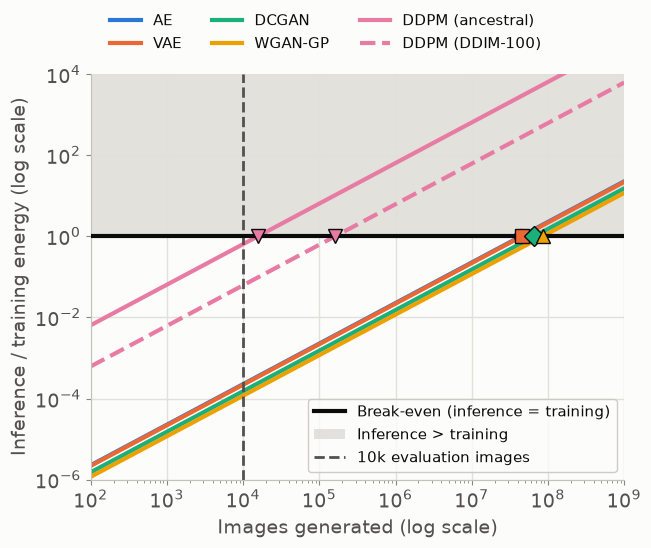

In [41]:
plot_breakeven(fixed)  # the same figure under the fixed budget (not in the paper)

# 6. Discussion: Numbers behind the Interpretation

## 6.1 Energy Follows Time: Average Power across Models

Average power (W) per model while training and while sampling, under both criteria.

In [42]:
power = native.pivot_table(index="model", columns="criterion", values=["power_w", "inference_w"], sort=False)
power.rename(index=A.NAMES, columns={"power_w": "Training power (W)", "inference_w": "Inference power (W)"}).round(0)

Training power (W)        Inference power (W)       
criterion              fixed target               fixed target
model                                                         
AE                     167.0  164.0               165.0  167.0
VAE                    163.0  162.0               165.0  167.0
DCGAN                  170.0  164.0               165.0  165.0
WGAN-GP                163.0  161.0               165.0  167.0
DDPM                   166.0  166.0               182.0  176.0

In [43]:
show({"Training power across models": span(power.power_w.stack(), unit=" W"),
      "Inference power across models": span(power.inference_w.stack(), unit=" W"),
      "Largest difference in training power (%)": 100 * (power.power_w.stack().max() / power.power_w.stack().min() - 1),
      "DDPM / AE, training time (×)": m.train_s.ddpm / m.train_s.ae, "DDPM / AE, training power (×)": m.power_w.ddpm / m.power_w.ae,
      "DDPM / AE, training energy (×)": E.ddpm / E.ae, "DDPM / AE, FLOPs per step (×)": m.flops_train_step.ddpm / m.flops_train_step.ae}, digits=2)

,value
Training power across models,161 to 170 W
Inference power across models,165 to 182 W
Largest difference in training power (%),5.51
"DDPM / AE, training time (×)",31.10
"DDPM / AE, training power (×)",1.00
"DDPM / AE, training energy (×)",30.94
"DDPM / AE, FLOPs per step (×)",173.21


## 6.2 The Price of Quality

A smartphone charge is taken as 0.012 kWh (43.2 kJ), following Luccioni et al. (2024).

In [44]:
PHONE_CHARGE_J = 0.012 * 3.6e6
show({"DCGAN to DDPM, FID (×)": m.final_fid.ddpm / m.final_fid.dcgan, "DCGAN to DDPM, training energy (×)": E.ddpm / E.dcgan,
      "DCGAN to DDPM, inference energy per image (×)": m.inference_j_per_1k.ddpm / m.inference_j_per_1k.dcgan,
      "DCGAN energy-to-target (kJ)": t.energy_to_target_j.dcgan / 1e3,
      "DCGAN energy-to-target / smartphone charge": t.energy_to_target_j.dcgan / PHONE_CHARGE_J,
      "VAE / DCGAN, FID (×), same network": m.final_fid.vae / m.final_fid.dcgan, "DCGAN / VAE, training energy (×)": E.dcgan / E.vae,
      "Target quality: AE / DDPM, QpJ training only (×)": t.qpj_train.ae / t.qpj_train.ddpm,
      "Target quality: AE / DDPM, FID (×)": t.final_fid.ae / t.final_fid.ddpm}, digits=2)

,value
"DCGAN to DDPM, FID (×)",0.48
"DCGAN to DDPM, training energy (×)",21.02
"DCGAN to DDPM, inference energy per image (×)","88,920.30"
DCGAN energy-to-target (kJ),9.75
DCGAN energy-to-target / smartphone charge,0.23
"VAE / DCGAN, FID (×), same network",4.41
"DCGAN / VAE, training energy (×)",1.43
"Target quality: AE / DDPM, QpJ training only (×)",2.41
"Target quality: AE / DDPM, FID (×)",3.97


## 6.3 Break-even Point at the Original DDPM Training Schedule

N* grows in proportion to training energy. Ho et al. (2020) trained for 800k steps at batch size 128; our budget is 152,597 steps at batch size 32.

In [45]:
schedule_ratio = (800_000 * 128) / (m.steps.ddpm * 32)  # images processed, original schedule / ours
show({"Images processed, original schedule / ours (×)": schedule_ratio, "Estimated N* at the original schedule (images)": round(schedule_ratio * m.n_star.ddpm)})

,value
"Images processed, original schedule / ours (×)",21.0
Estimated N* at the original schedule (images),"327,827"


## 6.4 Quality Cost of the Faster DDIM-100 Sampler

Under the target-quality criterion, the last periodic check uses 5,000 images and the final evaluation 10,000.
For the single-pass models both use the same sampler, so the difference shows the effect of the sample size alone.
For DDPM the check uses DDIM-100 and the final evaluation ancestral sampling.

In [46]:
checks = t[["last_check_fid", "final_fid"]].assign(difference=t.last_check_fid - t.final_fid)
checks.columns = ["Last check FID (5,000 images)", "Final FID (10,000 images)", "Difference"]
checks.rename(index=A.NAMES).round(2)

,"Last check FID (5,000 images)","Final FID (10,000 images)",Difference
model,,,
AE,49.24,48.26,0.99
VAE,49.61,48.89,0.72
DCGAN,38.81,37.69,1.12
WGAN-GP,47.20,45.32,1.88
DDPM,17.57,12.15,5.41


In [47]:
show({"DDIM-100 saving in inference energy (×)": m.inference_j_per_1k.ddpm / m.ddim_j_per_1k.ddpm,
      "Largest sample-size effect among single-pass models (FID points)": checks.drop("ddpm").Difference.max(),
      "DDPM difference, DDIM-100 versus ancestral (FID points)": checks.loc["ddpm", "Difference"]}, digits=2)

,value
DDIM-100 saving in inference energy (×),10.35
Largest sample-size effect among single-pass models (FID points),1.88
"DDPM difference, DDIM-100 versus ancestral (FID points)",5.41
